# What Type of Boletus Is It? 🍄

### Classificazione di quattro specie di porcini con fast.ai

**Prototipo didattico** · Computer vision · Transfer learning · Python

In questo notebook costruisco un classificatore di immagini che prova a distinguere quattro specie del genere *Boletus*: *B. aereus*, *B. edulis*, *B. pinophilus* e *B. reticulatus*.

L'esperimento riprende il metodo della prima lezione di [Practical Deep Learning for Coders](https://course.fast.ai/Lessons/lesson1.html): partire da un modello preaddestrato, costruire un dataset personale, osservare gli errori e migliorare progressivamente il progetto.

> **Ambito d'uso:** esercizio sperimentale di riconoscimento fotografico. Il modello **non** può determinare se un fungo sia commestibile o sicuro da consumare; l'identificazione micologica non deve basarsi su questa previsione.

**Domanda di ricerca:** quanto riesce a distinguere specie visivamente simili un modello preaddestrato, allenato su fotografie raccolte tramite una ricerca sul web?

**Cosa vedremo:** acquisizione dati → controlli di qualità → `DataBlock` → fine-tuning → valutazione → predizione su una fotografia nuova.

## Prima di iniziare — Dati, strumenti e riproducibilità

- **Strumenti:** Python 3.12, `ddgs`, `fastcore` e `fastai` (che utilizza PyTorch).
- **Dataset:** immagini scaricate da ricerche online, divise per specie in sottocartelle della directory `dataset/`.
- **Classi previste:** quattro specie del genere *Boletus*; l'eventuale cartella `Other` è inizialmente vuota e **non** rappresenta ancora una quinta classe addestrata.
- **Fotografia esterna di prova:** `test/boletusTest.jpeg`, fuori dalla directory `dataset/`.

**Nota di riproducibilità:** la ricerca DDGS restituisce risultati che possono cambiare nel tempo o non essere più raggiungibili. Rieseguendo le celle di download si può modificare il dataset, perciò i risultati qui documentati si riferiscono all'esecuzione salvata nel notebook originale. Anche con `seed=42`, la riproducibilità completa dell'addestramento non è garantita.

Per una futura versione pubblica, sarà utile aggiungere la provenienza, la licenza, la data di accesso e l'identificazione verificata delle singole immagini.

## 1. Ricerca automatica delle fotografie

La prima fase consiste nel trasformare una query testuale, per esempio `Boletus aereus photo`, in una lista di indirizzi da cui scaricare immagini.

La funzione `search_mushrooms()` utilizza `DDGS().images()` per ottenere risultati strutturati. Ogni risultato contiene informazioni sull'immagine e sulla pagina di origine; con `L(...).itemgot("image")` estraggo soltanto il campo che contiene l'URL diretto dell'immagine.

**Perché separare ricerca e download?** La ricerca restituisce *cosa* scaricare, mentre il download decide *dove* salvare i file. Tenere separate le due responsabilità rende il codice più facile da verificare e modificare.

**Limite:** un motore di ricerca può restituire immagini mal classificate, duplicate, ritoccate o protette da licenza. Il risultato della ricerca **non** equivale a un'identificazione botanica attendibile.

In [1]:
from ddgs import DDGS
from fastcore.all import *

def search_mushrooms(species, max_images=200):
    with DDGS() as ddgs:
        result = ddgs.images(species, max_results=max_images)

    return L(result).itemgot("image")

## 2. Definizione delle classi e organizzazione delle cartelle

Per addestrare un classificatore supervisionato devo associare a ogni immagine un'etichetta corretta. In questo progetto scelgo di usare il **nome della cartella** come etichetta.

Esempio: un file collocato in `dataset/Boletus_aereus/` riceverà la classe `Boletus_aereus`.

La funzione che segue automatizza la creazione delle cartelle. Utilizzo `Path` per comporre percorsi locali e `mkdir(exist_ok=True, parents=True)` per poter rieseguire l'operazione senza errori quando la cartella esiste già.

In [2]:
def create_directory(dir_name):
    dest = (PATH/dir_name)
    dest.mkdir(exist_ok=True, parents=True)

### Specie considerate

| Classe del modello | Nome scientifico | Ruolo nell'esperimento |
|---|---|---|
| `Boletus_aereus` | *Boletus aereus* | Specie inizialmente oggetto del progetto |
| `Boletus_edulis` | *Boletus edulis* | Specie simile da distinguere |
| `Boletus_reticulatus` | *Boletus reticulatus* | Specie simile da distinguere |
| `Boletus_pinophilus` | *Boletus pinophilus* | Specie simile da distinguere |

Il dizionario `mushrooms` consente di generare i nomi delle classi senza scrivere manualmente il percorso di ogni specie.

La cartella `Other` viene creata per possibili sviluppi futuri, ma per addestrare una classe «altro» servirebbero esempi accuratamente verificati di altre specie. Una classe «altro» non garantirebbe comunque il riconoscimento di tutti i funghi non presenti nel dataset.

In [3]:
from pathlib import Path
PATH = Path('dataset')

mushrooms = {
    "Boletus": [
        "aereus",
        "edulis",
        "reticulatus",
        "pinophilus"
    ]
}

dest = (PATH/"Other")
dest.mkdir(exist_ok=True, parents=True)



## 3. Download e ridimensionamento

Il ciclo seguente percorre le specie definite nel dizionario. Per ciascuna:

1. costruisce il nome della classe e la query di ricerca;
2. crea la relativa cartella, se necessario;
3. richiede **fino a 100 URL** e scarica le immagini recuperabili;
4. attende 30 secondi prima della ricerca successiva;
5. ridimensiona le immagini, imponendo una dimensione massima di 400 pixel.

Il numero di URL non coincide necessariamente con il numero di immagini salvate: alcuni download possono fallire. La pausa fra le richieste riduce la frequenza degli accessi, ma non garantisce l'assenza di blocchi o errori del servizio.

**Scelta progettuale:** salvare prima le immagini nelle cartelle delle specie rende semplice utilizzare poi `parent_label`. Come passo futuro sarebbe utile conservare anche un registro CSV degli URL, delle fonti e degli eventuali errori.

In [7]:
from fastai.vision.all import *
for genre, species in mushrooms.items():
    for specie in species:
        mushroom_name = f"{genre}_{specie}"
        search_query = f"{genre} {specie} photo"

        create_directory(mushroom_name)
        results = search_mushrooms(search_query, 100)

        download_images(PATH/mushroom_name, urls=results)
        time.sleep(30)
        resize_images(PATH/mushroom_name, max_size=400, dest=PATH/mushroom_name)


## 4. Controllo dell'integrità delle fotografie

Non tutti i file scaricati sono immagini utilizzabili: alcuni download possono produrre file incompleti o corrotti.

`get_image_files(PATH)` recupera le immagini presenti nel dataset, mentre `verify_images()` individua quelle che non si riescono ad aprire correttamente. Infine, il codice elimina i file segnalati.

**Risultato dell'esecuzione salvata:** è stato individuato e rimosso **1 file non valido**.

Questa verifica è **tecnica**, non tassonomica: un'immagine perfettamente leggibile potrebbe comunque mostrare una specie diversa da quella dichiarata dalla cartella. Prima di considerare attendibili le metriche, sarà necessario rivedere le etichette e gli eventuali duplicati.

In [10]:
failed = verify_images(get_image_files(PATH))
failed.map(Path.unlink)
len(failed)

1

## 5. Preparazione dei dati con `DataBlock`

Prima di addestrare il modello, fast.ai deve sapere quali sono gli input, quali sono le etichette e come suddividere i dati.

| Componente | Significato nel progetto |
|---|---|
| `ImageBlock` | Input: fotografia del fungo |
| `CategoryBlock` | Output: una delle quattro classi |
| `get_image_files` | Cerca ricorsivamente le immagini dentro `dataset/` |
| `parent_label` | Usa il nome della cartella madre come etichetta |
| `RandomSplitter(valid_pct=0.2, seed=42)` | Tiene da parte il 20% delle immagini per la validazione |
| `Resize(192, method='pad')` | Adatta la dimensione preservando le proporzioni |
| `bs=16` | Elabora gruppi di 16 immagini nel training |

La funzione `show_batch()` permette un primo controllo visivo dell'associazione tra fotografia e classe.

**Limite metodologico:** uno split casuale può collocare immagini duplicate o dello stesso esemplare sia nel training sia nella validazione. Per un esperimento più affidabile, occorre raggruppare per esemplare/osservazione e separare quei gruppi, oltre a verificare la rappresentatività delle classi.

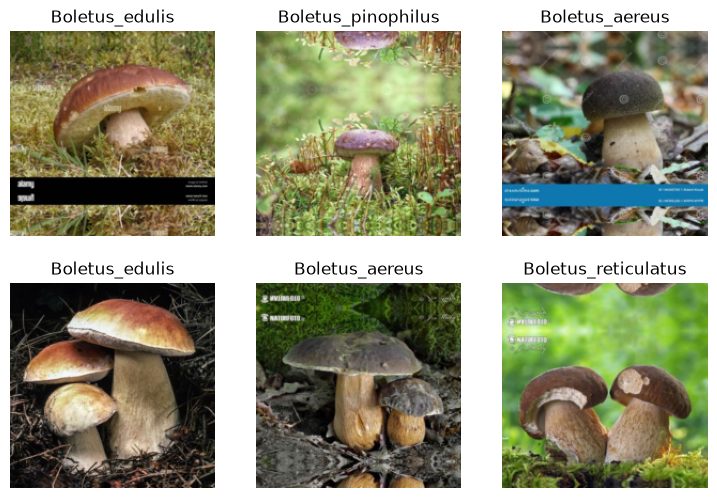

In [13]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192,method='pad')]
).dataloaders(PATH, bs=16)

dls.show_batch(max_n=6)

## 6. Modello e addestramento: perché ResNet18?

Utilizzo `vision_learner()` con **ResNet18**, una rete neurale convoluzionale già preaddestrata su un ampio dataset di immagini.

Questa scelta sfrutta il *transfer learning*: invece di imparare da zero caratteristiche visive generali (forme, bordi, texture), la rete parte da rappresentazioni già apprese e le adatta alle quattro specie.

`fine_tune(5)` esegue di norma una fase iniziale con il corpo della rete congelato, seguita da **5 epoche di fine-tuning**. Durante l'addestramento osservo:

- **training loss**: valore della funzione di perdita sui dati di addestramento;
- **validation loss**: valore della perdita su dati non usati per aggiornare i pesi;
- **error rate**: proporzione di esempi classificati erroneamente.

Un training loss basso non garantisce di per sé che il modello sappia riconoscere fotografie nuove: bisogna osservare soprattutto le metriche sulla validazione.

In [14]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(5)

epoch     train_loss  valid_loss  error_rate  time    
0         2.674386    1.550536    0.724138    00:03                                       
epoch     train_loss  valid_loss  error_rate  time    
0         1.337125    1.414879    0.655172    00:04                                       
1         1.244207    1.379641    0.551724    00:05                                       
2         1.100088    1.475031    0.586207    00:05                                       
3         0.928696    1.472069    0.551724    00:05                                       
4         0.760132    1.461664    0.551724    00:05                                       


### Risultati della prima esecuzione

I seguenti numeri sono trascritti dall'output **salvato** del training, e dovranno essere aggiornati se il notebook viene rieseguito su dati diversi.

| Fase | Epoca | Training loss | Validation loss | Error rate |
|---|---:|---:|---:|---:|
| Iniziale (freeze) | 0 | 2,6744 | 1,5505 | 72,41% |
| Fine-tuning | 0 | 1,3371 | 1,4149 | 65,52% |
| Fine-tuning | 1 | 1,2442 | **1,3796** | **55,17%** |
| Fine-tuning | 2 | 1,1001 | 1,4750 | 58,62% |
| Fine-tuning | 3 | 0,9287 | 1,4721 | **55,17%** |
| Fine-tuning | 4 | **0,7601** | 1,4617 | **55,17%** |

La training loss diminuisce in tutte le epoche, mentre la validation loss raggiunge il minimo all'epoca 1 del fine-tuning e successivamente aumenta. Il comportamento è **compatibile con un possibile overfitting**, ma non basta da solo a dimostrarlo: occorre controllare prima qualità, dimensioni e composizione del dataset.

Al termine del fine-tuning l'accuracy di validazione è circa **44,83%** (`1 − error_rate`). Il risultato indica che il modello non è ancora affidabile per distinguere queste specie.

## 7. Curve di apprendimento

Il grafico ottenuto con `learn.recorder.plot_loss()` aiuta a confrontare visivamente l'andamento delle due loss durante la fase registrata dal recorder.

**Che cosa cercare nel grafico?** Un andamento in cui la training loss continua a scendere, ma la validation loss si stabilizza o cresce, suggerisce che ulteriori epoche potrebbero non migliorare la generalizzazione.

Il grafico non sostituisce un test set esterno. Inoltre i valori dettagliati stampati al termine delle epoche e le curve sui batch hanno una diversa granularità.

<Axes: title={'center': 'learning curve'}, xlabel='steps', ylabel='loss'>

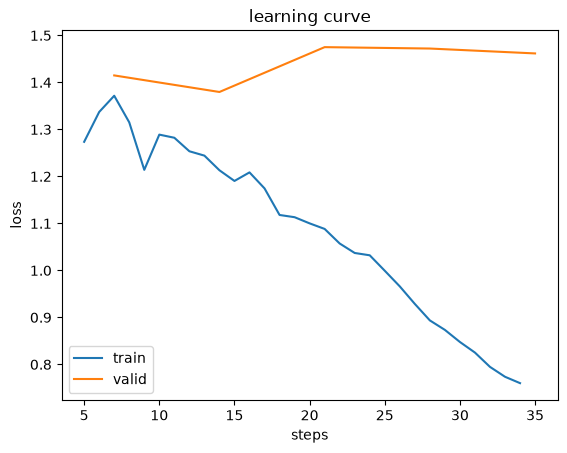

In [ ]:
learn.recorder.plot_loss()

## 8. Inferenza: riconoscere una fotografia non vista durante il training

Con `learn.predict()` passo al modello un'immagine e ricevo:

1. il nome della classe prevista;
2. il suo indice nel vocabolario delle classi;
3. un vettore con un punteggio per ciascuna classe.

La fotografia di prova viene letta da `test/boletusTest.jpeg`, una directory separata da `dataset/`.

**Output dell'esecuzione salvata:** classe prevista `Boletus_aereus`, punteggio circa **65,7%**. Questo punteggio esprime la preferenza del modello fra le sue classi, **non** una certezza del 65,7% che l'identificazione sia corretta, né un giudizio di commestibilità.

Il classificatore è a **insieme chiuso**: anche per un fungo appartenente a un'altra specie, può attribuire un punteggio elevato a una delle quattro classi conosciute.

In [ ]:
specie,_,probs = learn.predict(PILImage.create('test/boletusTest.jpeg'))
print(f'This is a: {specie}.')
print(f"Probability it's a {specie}: {probs[_]:.2f}")


This is a: Boletus_aereus.                                           
Probability it's a Boletus_aereus: 0.6570


## 9. Matrice di confusione: quali specie vengono scambiate?

L'**error rate globale** riassume quante previsioni sono errate, ma non dice quali specie il modello confonda maggiormente. La matrice di confusione fornisce questo dettaglio.

Nel grafico, le **righe** sono le specie effettive e le **colonne** quelle previste. La diagonale raccoglie le classificazioni corrette; gli elementi fuori diagonale rappresentano gli errori.

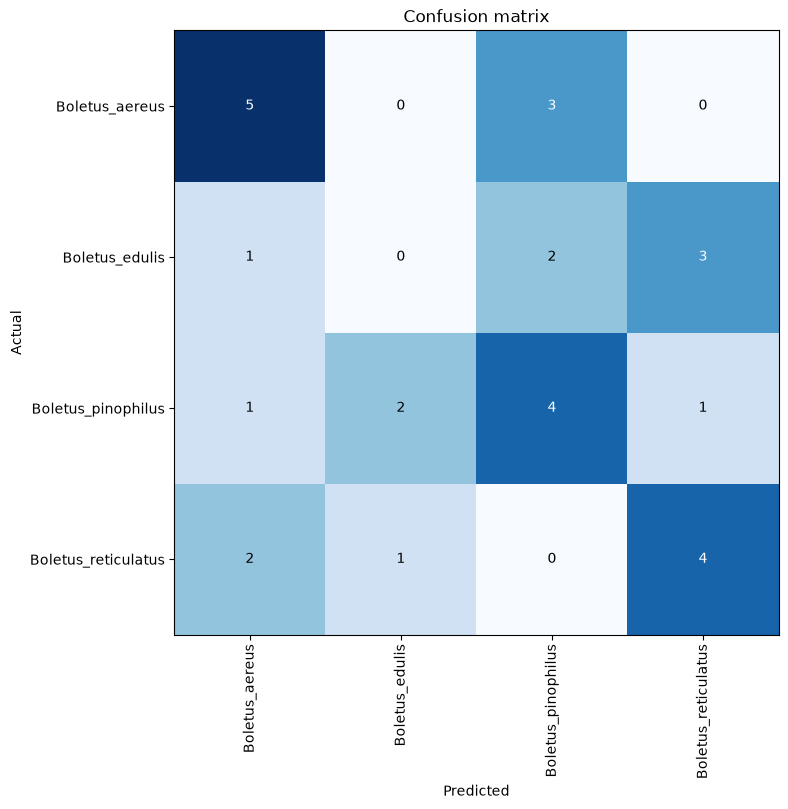

In [19]:
interp = ClassificationInterpretation.from_learner(learn)

interp.plot_confusion_matrix(figsize=(8, 8))

### Lettura della matrice salvata

Nell'esecuzione riportata la validazione contiene **29 immagini**. Le previsioni corrette sono **13 su 29**, coerenti con un'accuracy di circa **44,83%**.

| Specie effettiva | Immagini in validazione | Corrette | Osservazione |
|---|---:|---:|---|
| *Boletus aereus* | 8 | 5 | 3 immagini confuse con *B. pinophilus* |
| *Boletus edulis* | 6 | **0** | Nessuna immagine classificata correttamente |
| *Boletus pinophilus* | 8 | 4 | Errori distribuiti su altre tre classi |
| *Boletus reticulatus* | 7 | 4 | Alcune immagini confuse con *B. aereus* e *B. edulis* |

Il dato più evidente è la difficoltà su **B. edulis**. Prima di provare architetture più complesse, dovrei controllare le fotografie e le etichette di questa classe, la quantità di dati, le somiglianze fra specie e la presenza di duplicati. Il campione resta molto piccolo, quindi le percentuali per singola classe sono instabili.

## 10. Analisi degli errori più significativi

`plot_top_losses()` mostra le immagini del validation set che hanno contribuito maggiormente alla funzione di perdita, insieme alla classe prevista e a quella assegnata dal dataset.

Questa analisi serve a distinguere diversi possibili problemi:

- **Etichette imprecise:** la fotografia potrebbe non rappresentare la specie indicata.
- **Qualità o composizione:** il fungo può essere poco visibile, ritagliato o fotografato in condizioni difficili.
- **Somiglianza fra specie:** alcune caratteristiche morfologiche possono essere simili.
- **Artefatti e provenienza:** watermark, sfondi ricorrenti e fotografie di catalogo possono introdurre scorciatoie indesiderate.

Le immagini ad alta loss non sono automaticamente errate nei dati: occorre revisionarle una per una, confrontandole con identificazioni affidabili.

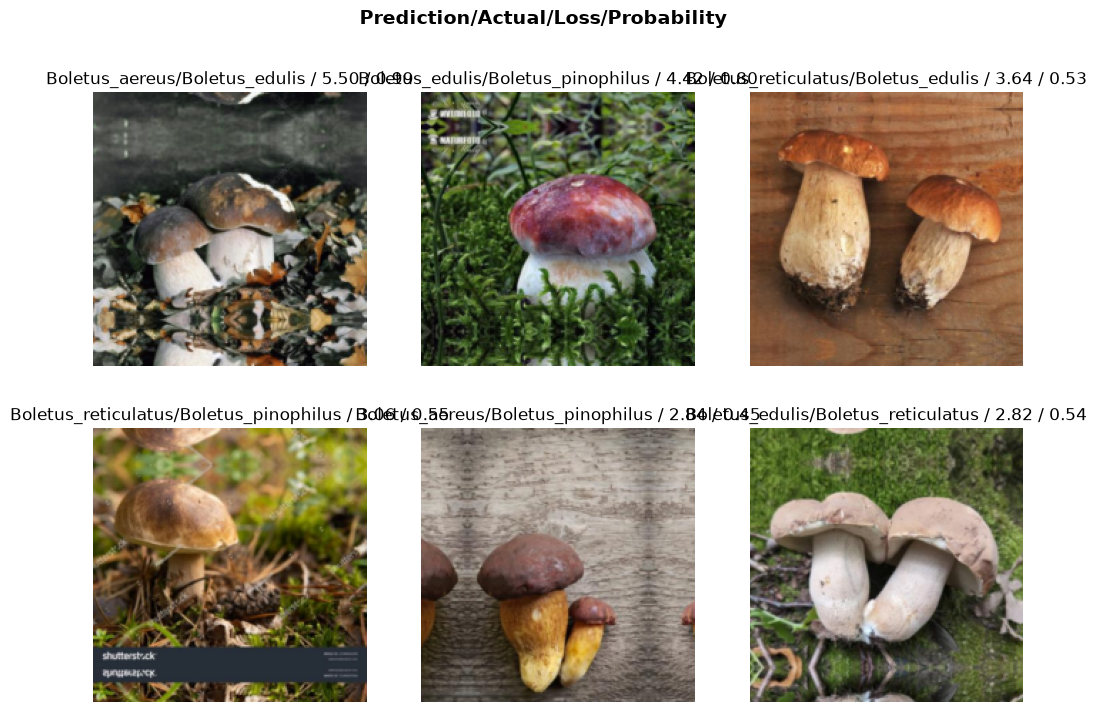

In [20]:
interp.plot_top_losses(6, nrows=2, figsize=(12, 8))